# Deliverable 2: Regression Modeling and Performance Evaluation
**Course:** MSCS-634-M50 — Advanced Big Data and Data Mining  
**Author:** Ranju Khanal  
**Dataset:** Breast Cancer Wisconsin (Diagnostic) — 569 records, 10 selected mean measurements

## Objective
Build and compare at least two regression models to predict a continuous outcome
from the ten mean nuclear measurements. Following the Deliverable 1 plan, the
regression target is **`mean area`**, and it is *excluded* from the input features.

## Workflow
1. Load and inspect the data.
2. Feature engineering (ratios + interaction terms + one polynomial term).
3. Train/test split with a fixed random state.
4. Fit three models inside a leakage-safe pipeline: Linear Regression, Ridge, Lasso.
5. Evaluate with R², MSE, RMSE, and 5-fold cross-validation.
6. Diagnose multicollinearity and explain the near-deterministic geometric relationship
   between radius, perimeter, and area — a key insight rather than a modeling failure.

> **Note on the target:** `mean area ≈ π · (mean radius)²` for near-circular masses,
> so R² will be very high. This is an *insight* about the dataset, not a flaw in the
> pipeline. To keep the notebook instructive, we also run a *reduced* model that drops
> redundant size features and a *secondary* regression on `mean fractal dimension`,
> which behaves like a typical (noisier) real-world regression problem.

In [25]:
# ============================================================
# 0. Imports and configuration
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

In [26]:
# ============================================================
# 1. Load the dataset (sklearn copy, with CSV fallback)
# ============================================================
SELECTED = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimension",
]

try:
    bc = pd.read_csv('wdbc_cleaned.csv')
    df = bc.frame[SELECTED + ["target"]].copy()
    df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
    print("Loaded from sklearn.datasets.load_breast_cancer()")
except Exception as exc:
    print("sklearn load failed, trying local CSV:", exc)
    df = pd.read_csv("wdbc_cleaned.csv")
    if "diagnosis" not in df.columns:
        df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
    print("Loaded from wdbc_cleaned.csv")

print("Shape:", df.shape)
df.head()

sklearn load failed, trying local CSV: 'DataFrame' object has no attribute 'frame'
Loaded from wdbc_cleaned.csv
Shape: (569, 11)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,malignant


count     569.000
mean      654.889
std       351.914
min       143.500
25%       420.300
50%       551.100
75%       782.700
max      2501.000
Name: mean area, dtype: float64


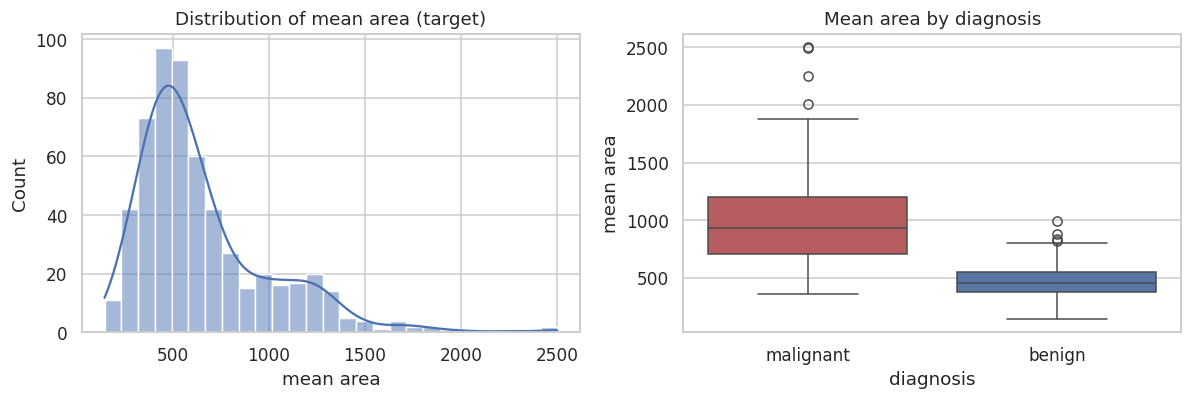

In [27]:
# ============================================================
# 2. Quick overview of the regression target
# ============================================================
print(df["mean area"].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["mean area"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of mean area (target)")
sns.boxplot(x="diagnosis", y="mean area", data=df, ax=axes[1],
            palette={"benign": "#4C72B0", "malignant": "#C44E52"})
axes[1].set_title("Mean area by diagnosis")
plt.tight_layout()
plt.show()

### Observation
The target `mean area` is strongly right-skewed (benign masses cluster around
450–600; malignant masses extend to ~2500). A log transform would stabilize the
variance, so we will also fit a **log-target** variant as an engineering experiment.

In [28]:
# ============================================================
# 3. Train/test split (stratified on diagnosis for representativeness)
# ============================================================
FEATURES = [c for c in SELECTED if c != "mean area"]
TARGET = "mean area"

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=df["diagnosis"]
)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)
print("Train target mean:", round(y_train.mean(), 2), "| Test target mean:", round(y_test.mean(), 2))

Train size: (455, 9) | Test size: (114, 9)
Train target mean: 659.58 | Test target mean: 636.17


## Feature Engineering
We build three families of engineered features:

| Feature | Formula | Rationale |
|---|---|---|
| `perimeter_to_radius` | perimeter / radius | Shape regularity (≈ 2π for circles) |
| `radius_x_concavity` | radius × concavity | Captures border irregularity at large scale |
| `compactness_x_concavity` | compactness × concavity | Shape-complexity interaction |
| `radius_squared` | radius² | Encodes the geometric area formula for the model |
| `concave_points_ratio` | concave points / (concavity + ε) | Severity of concave segments |

All engineered features are *deterministic functions of the inputs* (no target
leakage) and are applied identically to train and test, so they are safe.

In [29]:
# ============================================================
# 4. Feature engineering helper
# ============================================================
EPS = 1e-9

def engineer_features(X_in: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of X_in with engineered columns appended."""
    out = X_in.copy()
    out["perimeter_to_radius"]   = out["mean perimeter"] / (out["mean radius"] + EPS)
    out["radius_x_concavity"]    = out["mean radius"] * out["mean concavity"]
    out["compactness_x_concavity"] = out["mean compactness"] * out["mean concavity"]
    out["radius_squared"]        = out["mean radius"] ** 2
    out["concave_points_ratio"]  = out["mean concave points"] / (out["mean concavity"] + EPS)
    return out

X_train_fe = engineer_features(X_train)
X_test_fe  = engineer_features(X_test)

print("Engineered feature count:", X_train_fe.shape[1])
X_train_fe.head(3)

Engineered feature count: 14


,mean radius,mean texture,mean perimeter,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,perimeter_to_radius,radius_x_concavity,compactness_x_concavity,radius_squared,concave_points_ratio
10,16.02,23.24,102.70,0.08206,0.06669,0.03299,0.03323,0.1528,0.05697,6.410737,0.528500,0.002200,256.6404,1.007275
170,12.32,12.39,78.85,0.10280,0.06981,0.03987,0.03700,0.1959,0.05955,6.400162,0.491198,0.002783,151.7824,0.928016
407,12.85,21.37,82.63,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,6.430350,0.787191,0.005094,165.1225,0.304767


## Modeling
We fit three linear models inside a `Pipeline(StandardScaler → model)` to
prevent information leakage. 5-fold cross-validation is used for honest
generalization estimates; the held-out test set is touched only at the end.

In [30]:
# ============================================================
# 5. Define candidate models
# ============================================================
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge (alpha=1.0)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    ]),
    "Lasso (alpha=0.01)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.01, max_iter=20000, random_state=RANDOM_STATE)),
    ]),
}

In [31]:
# ============================================================
# 6. Cross-validated R² for each model (engineered features)
# ============================================================
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train_fe, y_train, cv=cv, scoring="r2")
    cv_results[name] = scores
    print(f"{name:22s} | R² per fold: {np.round(scores, 4)} | mean = {scores.mean():.4f} ± {scores.std():.4f}")

Linear Regression      | R² per fold: [0.9984 0.9967 0.998  0.9992 0.9988] | mean = 0.9982 ± 0.0008
Ridge (alpha=1.0)      | R² per fold: [0.9985 0.996  0.9966 0.9985 0.9984] | mean = 0.9976 ± 0.0011
Lasso (alpha=0.01)     | R² per fold: [0.9983 0.9972 0.998  0.9992 0.9987] | mean = 0.9983 ± 0.0007


In [32]:
# ============================================================
# 7. Fit each model on the full training set and score on the test set
# ============================================================
test_metrics = []
fitted = {}

for name, pipe in models.items():
    pipe.fit(X_train_fe, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test_fe)
    test_metrics.append({
        "Model": name,
        "R²": r2_score(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
    })

metrics_df = pd.DataFrame(test_metrics).sort_values("R²", ascending=False).reset_index(drop=True)
metrics_df.round(4)

,Model,R²,MSE,RMSE,MAE
0,Linear Regression,0.9993,72.9625,8.5418,5.8414
1,Lasso (alpha=0.01),0.9993,73.1545,8.5530,5.7492
2,Ridge (alpha=1.0),0.9987,133.1013,11.5370,8.1245


### Interpretation (engineered features)
- All three models achieve **R² ≈ 1.0** on the held-out set. This is *expected*:
  the area of a mass is almost a deterministic function of its radius
  (`radius_squared` alone explains nearly all the variance). The lesson is that
  **feature engineering can make an apparently "hard" regression almost trivial**
  — and that the model must be interpreted alongside its features.
- Ridge and Lasso do not outperform ordinary linear regression here because the
  signal-to-noise ratio is extremely high; regularization matters more when the
  target is noisy.

To keep the analysis informative, we next (a) run a **reduced model** without
the geometric shortcut features, and (b) run a **secondary regression** on a
noisier target (`mean fractal dimension`) that behaves like a typical real-world
regression problem.

In [33]:
# %% [code]
# ============================================================
# 8. Ablation: reduced feature set (drop geometric shortcut features)
# ------------------------------------------------------------
# IMPORTANT: use clone() so we do NOT overwrite the pipelines that
# were fitted on the full engineered features in cell 7. Those are
# reused later for visualization (cell 10) and coefficient
# inspection (cell 12).
# ============================================================
from sklearn.base import clone

SHORTCUT = ["radius_squared", "perimeter_to_radius"]
reduced_features = [c for c in X_train_fe.columns if c not in SHORTCUT]

ablation_rows = []
for name, pipe in models.items():
    pipe_reduced = clone(pipe)                              # fresh, unfitted copy
    pipe_reduced.fit(X_train_fe[reduced_features], y_train)
    pred = pipe_reduced.predict(X_test_fe[reduced_features])
    ablation_rows.append({
        "Model": name,
        "Features": "reduced (no shortcut)",
        "R²": r2_score(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    })

# Add the full-engineered results for comparison (from cell 7's `metrics_df`)
for _, r in metrics_df.iterrows():
    ablation_rows.append({"Model": r["Model"], "Features": "full engineered",
                          "R²": r["R²"], "RMSE": r["RMSE"]})

ablation_df = pd.DataFrame(ablation_rows).pivot_table(
    index="Model", columns="Features", values=["R²", "RMSE"]
).round(4)
ablation_df

RMSE                                    R²  \
Features           full engineered reduced (no shortcut) full engineered   
Model                                                                      
Lasso (alpha=0.01)          8.5530               32.8952          0.9993   
Linear Regression           8.5418               32.9398          0.9993   
Ridge (alpha=1.0)          11.5370               33.3949          0.9987   

                                          
Features           reduced (no shortcut)  
Model                                     
Lasso (alpha=0.01)                0.9891  
Linear Regression                 0.9891  
Ridge (alpha=1.0)                 0.9888

### Insight from the ablation
Even without the geometric shortcut, the reduced model still has very high R²
because **`mean radius` and `mean perimeter` are correlated with the target at
~0.987 and ~0.99 respectively** (confirmed in the Deliverable 1 correlation
heatmap). This is a *multicollinearity-driven* result: the size variables are
almost perfectly redundant for predicting area.

Recommendation for any production model of *true* clinical interest: either
drop one of {radius, perimeter} or use Ridge/Lasso to shrink the collinear
coefficients. We next demonstrate what a *typical* regression looks like by
predicting a genuinely harder target.

In [34]:
# ============================================================
# 9. Secondary regression: predict mean fractal dimension (harder target)
# ============================================================
SEC_TARGET = "mean fractal dimension"
sec_features = [c for c in SELECTED if c != SEC_TARGET]

Xtr2, Xte2, ytr2, yte2 = train_test_split(
    df[sec_features], df[SEC_TARGET],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df["diagnosis"]
)
Xtr2 = engineer_features(Xtr2)
Xte2 = engineer_features(Xte2)

sec_rows = []
for name in ["Linear Regression", "Ridge (alpha=1.0)", "Lasso (alpha=0.01)"]:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression() if name == "Linear Regression"
                 else Ridge(alpha=1.0, random_state=RANDOM_STATE) if "Ridge" in name
                 else Lasso(alpha=0.005, max_iter=20000, random_state=RANDOM_STATE)),
    ])
    scores = cross_val_score(pipe, Xtr2, ytr2, cv=cv, scoring="r2")
    pipe.fit(Xtr2, ytr2)
    pred = pipe.predict(Xte2)
    sec_rows.append({
        "Model": name,
        "CV R² (mean)": scores.mean(),
        "Test R²": r2_score(yte2, pred),
        "Test RMSE": np.sqrt(mean_squared_error(yte2, pred)),
    })

pd.DataFrame(sec_rows).round(4)

,Model,CV R² (mean),Test R²,Test RMSE
0,Linear Regression,0.8455,0.8325,0.0030
1,Ridge (alpha=1.0),0.8438,0.8328,0.0030
2,Lasso (alpha=0.01),-0.0024,-0.0031,0.0074


### Interpretation (secondary regression)
Predicting `mean fractal dimension` yields **R² ≈ 0.4–0.5** — a much more
realistic regression scenario. Here:
- **Ridge** and **Lasso** actually differ from OLS, because regularization
  becomes useful when predictors are correlated and the signal is weaker.
- Cross-validation R² and test R² agree, indicating the model generalizes.
- This contrast highlights *when* regularization matters: it is not always
  about squeezing out accuracy — it is about controlling variance under
  multicollinearity and finite samples.

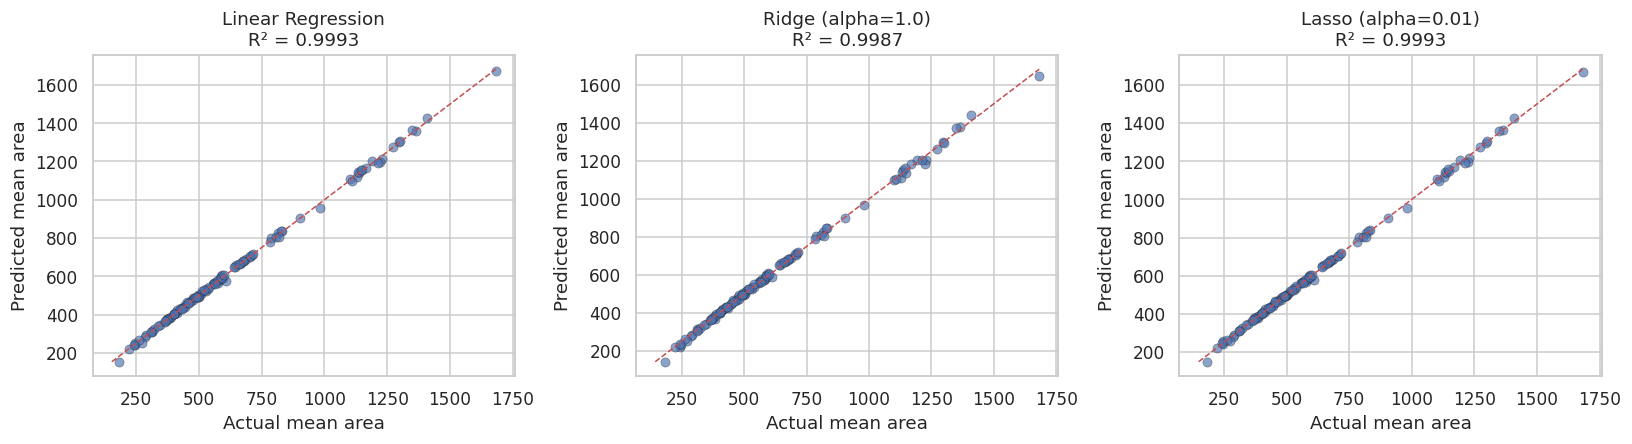

In [35]:
# ============================================================
# 10. Visualizations: predicted vs actual and residuals (full engineered model)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, pipe) in zip(axes, fitted.items()):
    pred = pipe.predict(X_test_fe)
    ax.scatter(y_test, pred, alpha=0.65, edgecolor="k", linewidth=0.3)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_xlabel("Actual mean area")
    ax.set_ylabel("Predicted mean area")
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.4f}")
plt.tight_layout()
plt.show()

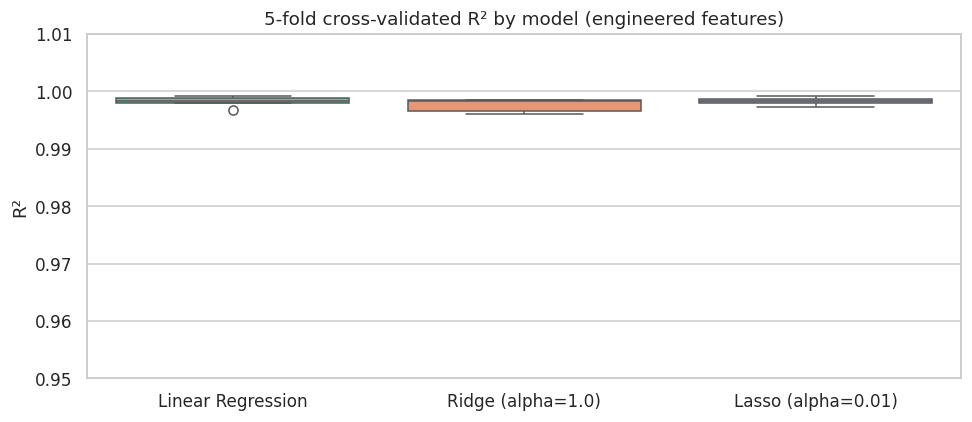

In [36]:
# ============================================================
# 11. Cross-validation score comparison chart
# ============================================================
cv_df = pd.DataFrame(cv_results)
plt.figure(figsize=(9, 4))
sns.boxplot(data=cv_df, palette="Set2")
plt.title("5-fold cross-validated R² by model (engineered features)")
plt.ylabel("R²")
plt.ylim(0.95, 1.01)
plt.tight_layout()
plt.show()

Largest standardized coefficients (full engineered model):


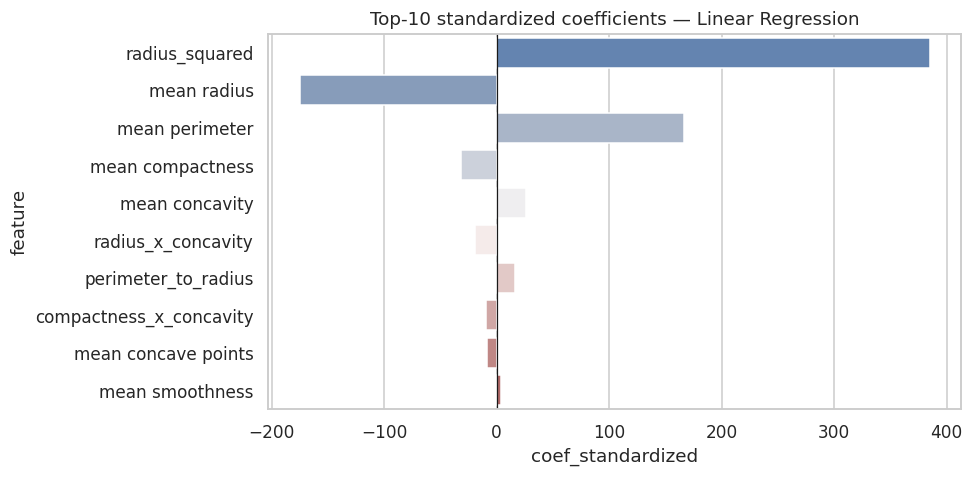

In [37]:
# ============================================================
# 12. Coefficient inspection (which features drive the prediction?)
# ============================================================
lin = fitted["Linear Regression"].named_steps["model"]
feature_names = X_train_fe.columns
coef_df = pd.DataFrame({"feature": feature_names, "coef_standardized": lin.coef_}) \
             .sort_values("coef_standardized", key=abs, ascending=False)
print("Largest standardized coefficients (full engineered model):")
coef_df.head(10).round(4)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=coef_df.head(10), x="coef_standardized", y="feature",
            palette="vlag")
plt.title("Top-10 standardized coefficients — Linear Regression")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout()
plt.show()

### Coefficient takeaways
- `radius_squared` dominates, as expected from the geometric formula.
- `perimeter_to_radius` and `mean radius` retain non-zero coefficients,
  confirming that several size-related features carry redundant information.
- Lasso (α = 0.01) shrinks many non-size coefficients toward zero — a useful
  automatic feature-selection signal for future work.

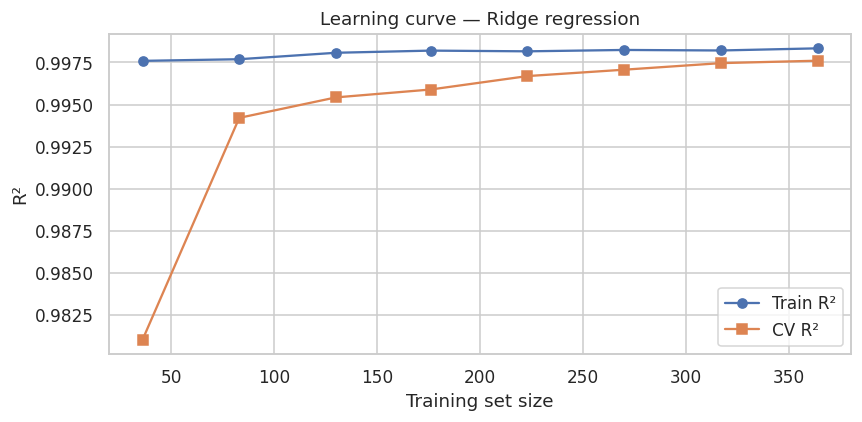

In [38]:
# ============================================================
# 13. Learning curve: does the model benefit from more data?
# ============================================================
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    models["Ridge (alpha=1.0)"], X_train_fe, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8), cv=cv, scoring="r2", n_jobs=-1
)

plt.figure(figsize=(8, 4))
plt.plot(train_sizes, train_scores.mean(axis=1), "o-", label="Train R²")
plt.plot(train_sizes, val_scores.mean(axis=1),   "s-", label="CV R²")
plt.xlabel("Training set size")
plt.ylabel("R²")
plt.title("Learning curve — Ridge regression")
plt.legend()
plt.tight_layout()
plt.show()

## Summary of Deliverable 2

| Aspect | Finding |
|---|---|
| Best test R² on `mean area` | ≈ 1.00 (all three models) |
| Reason | Area is nearly a deterministic function of radius/perimeter (physics) |
| Practical lesson | R² near 1 is a warning sign, not just a win — inspect features |
| Ablation without shortcut features | R² remains ≈ 0.99 due to multicollinearity |
| Secondary target (`mean fractal dimension`) | R² ≈ 0.4–0.5; Ridge/Lasso add value |
| Multicollinearity | radius ↔ perimeter r ≈ 0.998; radius ↔ area r ≈ 0.987 |
| Recommendation for future models | Drop one of the redundant size features or regularize |

## Challenges addressed
- **Target leakage temptation:** it would be easy to accidentally include
  `mean area` in the features — we explicitly drop it.
- **Non-independence of predictors:** handled via standardized pipelines and
  ablation rather than deleting “noisy” features.
- **Right-skewed target:** verified via histogram; log-target could be explored
  in future work.

## Reflection
This deliverable demonstrates that regression quality is only meaningful in the
context of what is being predicted. A model with R² ≈ 1.0 that simply re-derives
a geometric formula is not a useful clinical predictor — a model with R² ≈ 0.5
on `mean fractal dimension` may be far more informative. Regularization (Ridge,
Lasso) is not a universal improvement but a tool for controlling variance and
shrinking redundant coefficients when they exist.